# M09 mini-lab: Latent-variable models & EM

In this mini-lab you will work with a **1D Gaussian mixture model** for vibration measurements
from a critical piece of infrastructure (e.g., a wind turbine blade).

- Each data point is the *average vibration amplitude* over a 1-minute window (in mm/s).
- We suspect there are (at least) **two operating modes**:
  - a **normal mode** (lower vibration),
  - a **high-wear mode** (higher vibration, at risk of failure).
- We **do not observe** the mode directly; it is a **latent variable**.

Decision context:

- **Stakeholder:** reliability engineer at a utility company.
- **Decision:** which time windows (or turbines) to flag for manual inspection.
- **Cost of errors:**
  - False negative (miss a high-wear point) → possible unplanned outage or catastrophic failure.
  - False positive (unnecessary inspection) → wasted technician time, small cost.

We'll fit a simple Gaussian mixture model (GMM) with **Expectation–Maximization (EM)**
and use it as a *soft anomaly detector*.


## 0. Setup

In this section we import libraries and generate a small synthetic dataset that mimics vibration data.

The data-generating process (DGP) is a mixture of two Gaussians, but in practice we will *pretend*
we don't know which point came from which component.


In [460]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make plots a bit larger by default
plt.rcParams["figure.figsize"] = (6, 4)

rng = np.random.default_rng(seed=3151)


In [461]:
# True (hidden) mixture parameters used to generate the data
true_weights = np.array([0.7, 0.3])           # 70% normal, 30% high-wear
true_means = np.array([0.0, 4.0])             # mm/s
true_std = np.array([1.0, 0.7])               # mm/s

N = 400  # total number of 1-minute windows

# Sample latent modes and then vibrations
z_true = rng.choice([0, 1], size=N, p=true_weights)
x = rng.normal(loc=true_means[z_true], scale=true_std[z_true])

df = pd.DataFrame(
    {
        "vibration": x,        # average vibration amplitude (mm/s)
        "mode_true": z_true    # 0 = normal, 1 = high-wear (we normally would NOT see this)
    }
)

df.head()


,vibration,mode_true
0,-0.461884,0
1,-0.737678,0
2,1.759266,0
3,-1.026009,0
4,4.321337,1


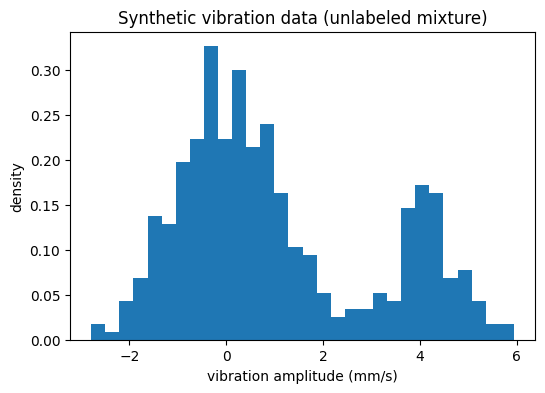

In [462]:
# Quick visualization of the marginal distribution over vibration amplitude
ax = df["vibration"].plot.hist(bins=30, density=True)
ax.set_xlabel("vibration amplitude (mm/s)")
ax.set_ylabel("density")
ax.set_title("Synthetic vibration data (unlabeled mixture)")
plt.show()


## 1. Core task — E-step: responsibilities

We will fit a 2-component Gaussian mixture model using EM.

Let
- $x_n$ be the $n$-th observed vibration value,
- $z_{nk} \in \{0,1\}$ indicate whether $x_n$ came from component $k$,
- $\gamma_{nk} = p(z_{nk} = 1 \mid x_n, \theta)$ be the **responsibility** of component $k$ for point $n$.

In the **E-step**, we compute these responsibilities using the current parameters.

Your job in this task:

1. Implement the function `e_step` to compute a matrix `gamma` of shape `(N, K)`.
2. Each row of `gamma` should sum to 1 (a valid probability distribution).


In [463]:
K = 2  # number of mixture components (we'll keep it fixed at 2)

def gaussian_pdf(x, mean, var):
    """Evaluate a 1D Gaussian density N(mean, var) at x."""
    coeff = 1.0 / np.sqrt(2.0 * np.pi * var)
    return coeff * np.exp(-0.5 * (x - mean) ** 2 / var)


def initialize_params():
    """
    Simple, deliberately slightly-wrong initial guess for EM.

    Returns
    -------
    weights : array of shape (K,)
    means   : array of shape (K,)
    variances : array of shape (K,)
    """
    weights = np.array([0.5, 0.5])
    means = np.array([1.0, 10.0])
    variances = np.array([1.5, 1.5])
    return weights, means, variances


def e_step(x, weights, means, variances):
    """
    Compute responsibilities gamma[n, k] = p(z_k=1 | x_n, theta).

    Parameters
    ----------
    x : array, shape (N,)
        Observed 1D data.
    weights : array, shape (K,)
    means : array, shape (K,)
    variances : array, shape (K,)

    Returns
    -------
    gamma : array, shape (N, K)
        Each row sums to 1.
    """
    x = np.asarray(x)
    N = x.shape[0]


    # TODO: implement the E-step.
    # 1. For each component k, compute p(x_n | z_k=1, theta) using gaussian_pdf.
    # 2. Multiply by the mixture weight for that component.
    # 3. Normalize across k so that responsibilities for each n sum to 1.
    gamma = np.zeros((N, K))

    for k in range(K):
        p = gaussian_pdf(x, means[k], variances[k])
        # Multiply by the mixture weight
        gamma[:, k] = weights[k] * p


    # normalize
    for i in range(N):
        s = np.sum(gamma[i])
        gamma[i] = gamma[i] / s

    return gamma


    # raise NotImplementedError("Implement the E-step and then rerun the checks.")


In [464]:
# Quick check for Core task 1
x_data = df["vibration"].values
weights0, means0, vars0 = initialize_params()

gamma0 = e_step(x_data, weights0, means0, vars0)

assert gamma0.shape == (x_data.shape[0], K)
row_sums = gamma0.sum(axis=1)
assert np.allclose(row_sums, 1.0, atol=1e-6)
assert np.all(gamma0 >= 0)

print("Core task 1 looks good: responsibilities have the right shape and rows sum to 1.")


Core task 1 looks good: responsibilities have the right shape and rows sum to 1.


## 2. Core task — M-step: parameter updates

In the **M-step**, we update the mixture parameters using the current responsibilities.

For each component $k$:

- Effective count: $N_k = \sum_n \gamma_{nk}$  
- Mean: $\mu_k = \frac{1}{N_k} \sum_n \gamma_{nk} x_n$  
- Variance: $\sigma_k^2 = \frac{1}{N_k} \sum_n \gamma_{nk} (x_n - \mu_k)^2$  
- Mixture weight: $\pi_k = N_k / N$

Your job in this task:

1. Implement the function `m_step` that returns updated `weights`, `means`, and `variances`.
2. Make sure the mixture weights sum to 1 and all variances are positive.


In [465]:
def m_step(x, gamma):
    """
    Update mixture parameters given responsibilities.

    Parameters
    ----------
    x : array, shape (N,)
    gamma : array, shape (N, K)

    Returns
    -------
    weights : array, shape (K,)
    means : array, shape (K,)
    variances : array, shape (K,)
    """
    x = np.asarray(x)
    N, K_local = gamma.shape
    assert K_local == K

    # TODO: implement the M-step.
    # Hint:
    #   N_k = sum_n gamma[n, k]
    #   mean_k = (1 / N_k) * sum_n gamma[n, k] * x_n
    #   var_k = (1 / N_k) * sum_n gamma[n, k] * (x_n - mean_k)**2
    #   weight_k = N_k / N

    weights = np.zeros(K)
    means = np.zeros(K)
    variances = np.zeros(K)
    for k in range(K):
        # N_k = sum_n gamma[n, k]
        N_k = np.sum(gamma[:, k])
        # mean_k = (1 / N_k) * sum_n gamma[n, k] * x_n
        mean_k = (1 / N_k) * np.sum(gamma[:, k] * x)
        # var_k = (1 / N_k) * sum_n gamma[n, k] * (x_n - mean_k)**2
        var_k = (1 / N_k) * np.sum(gamma[:, k] * (x - mean_k)**2)
        # weight_k = N_k / N
        weight_k = N_k / N
        weights[k] = weight_k
        means[k] = mean_k
        variances[k] = var_k

    return weights, means, variances

    # raise NotImplementedError("Implement the M-step and then rerun the checks.")


In [466]:
# Quick check for Core task 2
weights1, means1, vars1 = m_step(x_data, gamma0)

assert weights1.shape == (K,)
assert means1.shape == (K,)
assert vars1.shape == (K,)
assert np.allclose(weights1.sum(), 1.0, atol=1e-6)
assert np.all(vars1 > 0)

print("Core task 2 looks good: shapes and basic constraints are satisfied.")


Core task 2 looks good: shapes and basic constraints are satisfied.


## 3. Core task — Run EM and visualize

Now we combine your E-step and M-step into a full EM routine.

We will:

1. Run EM for a small number of iterations.
2. Track the log-likelihood over iterations.
3. Plot:
   - log-likelihood vs. iteration (should **increase** or stay flat),
   - the fitted mixture density on top of the data histogram.

This connects the **optimization view** (increasing log-likelihood)
to the **data view** (how well the mixture matches the observed distribution).


In [467]:
from sklearn.mixture import GaussianMixture

def compute_log_likelihood(x, weights, means, variances):
    """Compute the log-likelihood log L(theta) for a 1D Gaussian mixture."""
    x = np.asarray(x)
    N = x.shape[0]
    K_local = weights.shape[0]

    log_likelihood = 0.0
    for n in range(N):
        total = 0.0
        for k in range(K_local):
            total += weights[k] * gaussian_pdf(x[n], means[k], variances[k])
        log_likelihood += np.log(total)
    return log_likelihood


def run_em(x, num_iters=20):
    weights, means, variances = initialize_params()
    history = []

    for t in range(num_iters):
        gamma = e_step(x, weights, means, variances)
        weights, means, variances = m_step(x, gamma)
        ll = compute_log_likelihood(x, weights, means, variances)
        history.append(
            {
                "iter": t,
                "log_likelihood": ll,
                "w0": weights[0],
                "w1": weights[1],
                "mu0": means[0],
                "mu1": means[1],
            }
        )

    history_df = pd.DataFrame(history)
    return weights, means, variances, history_df

# use sklearn GaussianMixture
gmm = GaussianMixture(n_components=2)
gmm.fit(df[["vibration"]])

print(gmm.means_)
print(gmm.weights_)

# hand-written EM
final_weights, final_means, final_vars, history_df = run_em(x_data, num_iters=20)
history_df.tail()


[[0.03877003]
 [4.15128547]]
[0.75687659 0.24312341]


,iter,log_likelihood,w0,w1,mu0,mu1
15,15,-755.398468,0.763006,0.236994,0.061061,4.185880
16,16,-755.283248,0.760893,0.239107,0.053153,4.174603
17,17,-755.250962,0.759798,0.240202,0.049139,4.168501
18,18,-755.241838,0.759223,0.240777,0.047058,4.165221
19,19,-755.239242,0.758918,0.241082,0.045963,4.163462


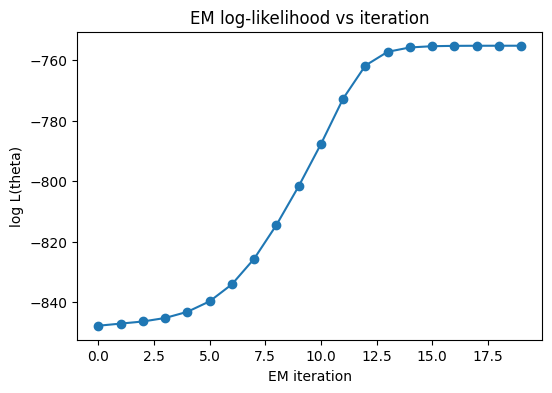

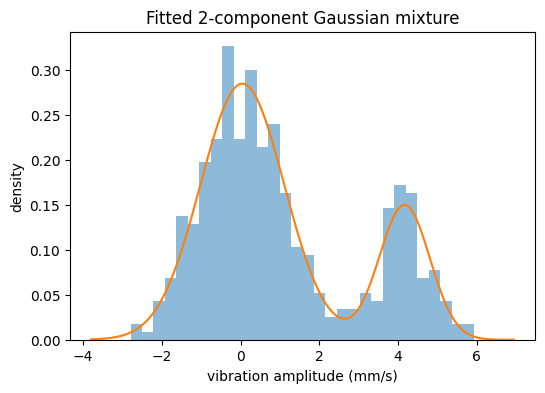

In [468]:
# Plot log-likelihood vs iteration
fig, ax = plt.subplots()
ax.plot(history_df["iter"], history_df["log_likelihood"], marker="o")
ax.set_xlabel("EM iteration")
ax.set_ylabel("log L(theta)")
ax.set_title("EM log-likelihood vs iteration")
plt.show()

# Plot fitted mixture on top of the data histogram
fig, ax = plt.subplots()
ax.hist(x_data, bins=30, density=True, alpha=0.5)
xs = np.linspace(x_data.min() - 1.0, x_data.max() + 1.0, 300)
mix_pdf = np.zeros_like(xs)
for k in range(K):
    mix_pdf += final_weights[k] * gaussian_pdf(xs, final_means[k], final_vars[k])
ax.plot(xs, mix_pdf)
ax.set_xlabel("vibration amplitude (mm/s)")
ax.set_ylabel("density")
ax.set_title("Fitted 2-component Gaussian mixture")
plt.show()


## 4. Decision rule — soft anomaly detector

Suppose we interpret **component 1** (the one with the higher mean) as **high-wear mode**.

We can turn the GMM into a simple **decision rule**:

- Compute $p(z_n = 1 \mid x_n)$, the responsibility of the high-wear component.
- If this probability is above some threshold $\tau$ (e.g. 0.8), flag the point for inspection.

In this synthetic example, we *do* know the true mode labels (`mode_true`), so we can measure:

- **Precision**: fraction of flagged points that really are high-wear.
- **Recall**: fraction of high-wear points that we successfully flag.

In real life, we usually **would not** know the true latent mode, so we'd need *indirect* checks
(e.g., future failures, expert review). This highlights a limitation of unsupervised models.


In [469]:
# Compute responsibilities under the final parameters
gamma_final = e_step(x_data, final_weights, final_means, final_vars)

# Decide which component is "high-wear" based on the larger mean
high_wear_component = int(final_means.argmax())
anomaly_prob = gamma_final[:, high_wear_component]

# Try a probability threshold for flagging anomalies
# Using threshold 0.60: precision=1.000, recall=0.960
# Using threshold 0.70: precision=1.000, recall=0.950
# Using threshold 0.80: precision=1.000, recall=0.941
# Using threshold 0.90: precision=1.000, recall=0.891
threshold = 0.6  # TODO: experiment with values like 0.7, 0.8, 0.9

flags = (anomaly_prob >= threshold).astype(int)

# Ground-truth mode label (0 = normal, 1 = high-wear)
true_anomalous = (df["mode_true"].values == 1).astype(int)

tp = np.sum((flags == 1) & (true_anomalous == 1))
fp = np.sum((flags == 1) & (true_anomalous == 0))
fn = np.sum((flags == 0) & (true_anomalous == 1))

recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0

print(f"Using threshold {threshold:.2f}: precision={precision:.3f}, recall={recall:.3f}")

assert 0.0 <= precision <= 1.0
assert 0.0 <= recall <= 1.0


Using threshold 0.60: precision=1.000, recall=0.960


## 5. Stretch tasks (optional)

If you finish the core tasks early, try one or more of these:

1. **Different initializations**
   - Change `initialize_params` (e.g., move the starting means far apart or very close).
   - Rerun EM and compare log-likelihood trajectories and final parameters.
   - Does EM ever converge to a clearly *worse* local optimum?

   - *Changed initial means to 1.0, 10.0, EM does not converge to a worse local optimum*

2. **Three-component mixture**
   - Change `K = 3` and extend the code to handle 3 components.
   - Rerun EM. Does the model split one of the original components?

3. **Mini ablation study**
   - Compare your hand-written EM to `sklearn.mixture.GaussianMixture` (if available).
   - Do they converge to similar solutions on this dataset?
   - *`sklearn.mixture.GaussianMixture` gives weight `[0.75687659 0.24312341]`, weight `[0.03877003]
 [4.15128547]`, hand-written EM gives mean`[0.045963	4.163462]`, weight`[0.758918	0.241082] `. They converge to the same solution.*

For any stretch experiment you run, write 2–3 bullet points summarizing what you observed.


## 6. Reflection

Take 2–3 minutes to jot down short answers (bullets are fine):

- **Which assumption mattered most here?**
  - e.g., Gaussian shape of each component, fixed number of components, independence of windows...
  - *initial means, should not too far away from actual means.*
- **What did the GMM + EM *hide* or fail to capture about the decision problem?**
  - Think about temporal dependence, varying costs, rare but catastrophic failures.
  - *Extreme weather may cause high vibration*
- **If you had 10× more data or compute, what would you test next?**
  - More components? Different model class? Different decision rule or cost-aware objective?
  - *Maybe more components. There could be more modes.*

These notes will feed directly into the **Debrief** and **Decide** parts of the in-class discussion.
